In [9]:
import pandas as pd
df = pd.read_excel(
    "Lab Session Data (1).xlsx",
    sheet_name="marketing_campaign")
print(df.head())

     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

           Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  \
0  2012-04-09 00:00:00       58       635  ...                  7   
1  2014-08-03 00:00:00       38        11  ...                  5   
2           21-08-2013       26       426  ...                  4   
3  2014-10-02 00:00:00       26        11  ...                  6   
4           19-01-2014       94       173  ...                  5   

   AcceptedCmp3  AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  \
0             0             0            

In [12]:
#a2-labelencoding

from sklearn.preprocessing import LabelEncoder
def label_encode(data, columns):
    data = data.copy()
    encoder = LabelEncoder()
    for col in columns:
        data[col] = encoder.fit_transform(data[col])
    return data

cat_cols = ["Education", "Marital_Status"]
label_data = label_encode(df, cat_cols)
print(label_data.head())

     ID  Year_Birth  Education  Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957          2               4  58138.0        0         0   
1  2174        1954          2               4  46344.0        1         1   
2  4141        1965          2               5  71613.0        0         0   
3  6182        1984          2               5  26646.0        1         0   
4  5324        1981          4               3  58293.0        1         0   

           Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  \
0  2012-04-09 00:00:00       58       635  ...                  7   
1  2014-08-03 00:00:00       38        11  ...                  5   
2           21-08-2013       26       426  ...                  4   
3  2014-10-02 00:00:00       26        11  ...                  6   
4           19-01-2014       94       173  ...                  5   

   AcceptedCmp3  AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  \
0             0             0            

In [14]:
#a2-onehotencoding

import pandas as pd
def one_hot_encode(data, columns):
    return pd.get_dummies(data, columns=columns)

cat_cols = ["Education", "Marital_Status"]
onehot_data = one_hot_encode(df, cat_cols)
print(onehot_data.head())

     ID  Year_Birth   Income  Kidhome  Teenhome          Dt_Customer  Recency  \
0  5524        1957  58138.0        0         0  2012-04-09 00:00:00       58   
1  2174        1954  46344.0        1         1  2014-08-03 00:00:00       38   
2  4141        1965  71613.0        0         0           21-08-2013       26   
3  6182        1984  26646.0        1         0  2014-10-02 00:00:00       26   
4  5324        1981  58293.0        1         0           19-01-2014       94   

   MntWines  MntFruits  MntMeatProducts  ...  Education_Master  Education_PhD  \
0       635         88              546  ...             False          False   
1        11          1                6  ...             False          False   
2       426         49              127  ...             False          False   
3        11          4               20  ...             False          False   
4       173         43              118  ...             False           True   

   Marital_Status_Absurd  

In [16]:
#a3

def dataset_shape(data):
    return data.shape

label_data = label_encode(df, cat_cols)
onehot_data = one_hot_encode(df, cat_cols)
print("Original :", dataset_shape(df))
print("Label :", dataset_shape(label_data))
print("One Hot :", dataset_shape(onehot_data))

Original : (2240, 29)
Label : (2240, 29)
One Hot : (2240, 40)


In [19]:
#a4

import numpy as np
def minkowski_distance(a, b, p):
    a = np.array(a)
    b = np.array(b)
    return (np.sum(np.abs(a - b) ** p)) ** (1 / p)

numeric_data = df.select_dtypes(include="number").dropna()
v1 = numeric_data.iloc[0].values
v2 = numeric_data.iloc[1].values
d = minkowski_distance(v1, v2, 2)
print("Distance =", d)

Distance = 12290.371231171172


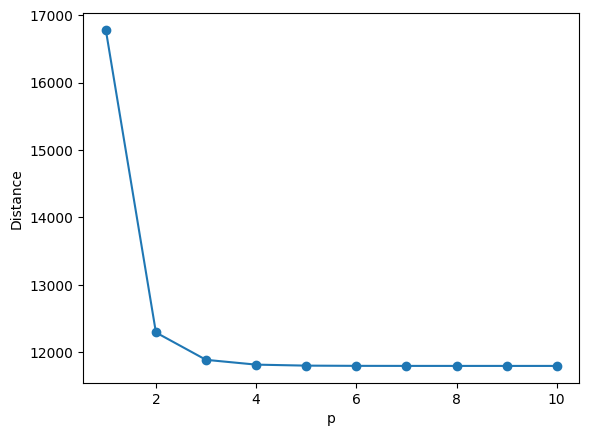

In [21]:
#a5

import matplotlib.pyplot as plt
def distance_values(a, b):
    values = []
    for p in range(1,11):
        values.append(minkowski_distance(a,b,p))
    return values

dist = distance_values(v1,v2)
plt.plot(range(1,11),dist,marker='o')
plt.xlabel("p")
plt.ylabel("Distance")
plt.show()

In [23]:
#a6

from scipy.spatial.distance import minkowski
def compare_distance(a,b,p):
    own = minkowski_distance(a,b,p)
    scipy = minkowski(a,b,p)
    return own, scipy

x,y = compare_distance(v1,v2,2)
print("Own :",x)
print("Scipy :",y)

Own : 12290.371231171172
Scipy : 12290.371231171172


In [26]:
#a7

import numpy as np
def dot_product(a, b):
    return np.sum(a * b)
def vector_norm(a):
    return np.sqrt(np.sum(a ** 2))

num = df.select_dtypes(include="number").dropna().to_numpy()
v1 = num[0]
v2 = num[1]
print("Our Dot :", dot_product(v1, v2))
print("NumPy Dot :", np.dot(v1, v2))
print("Our Norm v1 :", vector_norm(v1))
print("NumPy Norm v1 :", np.linalg.norm(v1))
print("Our Norm v2 :", vector_norm(v2))
print("NumPy Norm v2 :", np.linalg.norm(v2))

Our Dot : 2710194336.0
NumPy Dot : 2710194336.0
Our Norm v1 : 58439.10812974476
NumPy Norm v1 : 58439.10812974476
Our Norm v2 : 46436.11243418208
NumPy Norm v2 : 46436.11243418208


In [28]:
#a8

import numpy as np
def statistics(data):
    mean = np.sum(data) / len(data)
    variance = np.sum((data - mean) ** 2) / len(data)
    std = np.sqrt(variance)
    return mean, variance, std

feature = df["Income"].dropna().to_numpy()
mean, var, std = statistics(feature)
print("Mean :", mean)
print("Variance :", var)
print("Standard Deviation :", std)

Mean : 52247.25135379061
Variance : 633397830.1872725
Standard Deviation : 25167.396174162965


In [31]:
#a9

mean, var, std = statistics(feature)
print("Mean :", mean)
print("NumPyMean :", np.mean(feature))

print("Std :", std)
print("NumPy Std :", np.std(feature))

Mean : 52247.25135379061
NumPyMean : 52247.25135379061
Std : 25167.396174162965
NumPy Std : 25167.396174162965


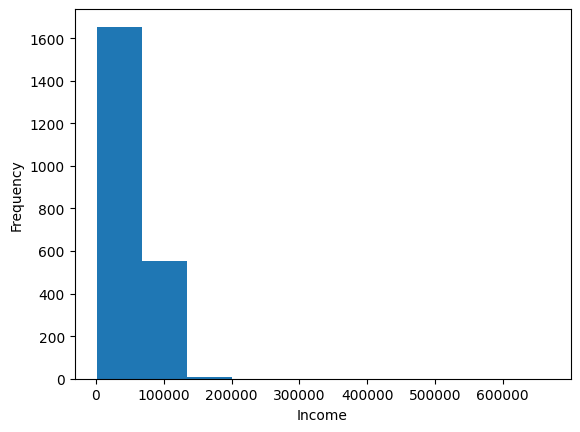

Mean : 52247.25135379061
Variance : 633397830.1872725


In [33]:
#a10

import matplotlib.pyplot as plt
def histogram(feature, bins):
    plt.hist(feature, bins=bins)
    plt.xlabel("Income")
    plt.ylabel("Frequency")
    plt.show()

histogram(feature, 10)
mean, var, std = statistics(feature)
print("Mean :", mean)
print("Variance :", var)

In [34]:
#a11

import numpy as np
def kmeans(data, k, iterations):
    centroids = data[:k]
    for _ in range(iterations):
        distance = np.linalg.norm(data[:, None] - centroids, axis=2)
        labels = np.argmin(distance, axis=1)
        new_centroids = np.array([
            data[labels == i].mean(axis=0)
            for i in range(k)])
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids
    return labels, centroids

X = df[["Income", "MntWines"]].dropna().to_numpy()
labels, centroids = kmeans(X, 3, 100)
print("Labels")
print(labels)
print("Centroids")
print(centroids)

Labels
[0 0 2 ... 0 2 0]
Centroids
[[5.56852568e+04 3.47049383e+02]
 [2.98794719e+04 3.90107527e+01]
 [8.02561213e+04 6.36768014e+02]]
